[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Auditoría de calidad de `titanic` y `penguins`.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo I: *Datos y su calidad*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se aplicará la auditoría de calidad completa a `titanic` y a `penguins`, y se generará el archivo `data/penguins_limpio.csv` que usan los *notebooks* siguientes.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* 🟢 **Ejercicio básico:** lo que todos deben dominar.
* 🔴 **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencia de la API: curso py311.

Los métodos de limpieza (`isna`, `notna`, `fillna`, `interpolate`, `dropna`, `duplicated`, `drop_duplicates`, …) se explican uno por uno en [py311 · 20 Limpieza y datos faltantes](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb), y el accesor `.str` en [py311 · 23 El accesor `str` de *pandas*](https://github.com/PythonistaMX/py311/blob/main/23_el_accesor_str_de_pandas.ipynb). Aquí se usan sin repasarlos a detalle: la sesión se dedica a **decidir** qué hacer con cada problema de calidad y a medir las consecuencias.

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3. Allá las columnas de texto aparecen como `object` y se usa `inplace=True`; aquí el texto es `str` y se **reasigna** (`df["col"] = df["col"].fillna(...)`) o se usa `df.loc[...] = ...`, como se explicó en la sección 1.1 de `03_pandas_3_esencial.ipynb`.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)

* La siguiente celda leerá `penguins` y `titanic` y mostrará su forma.

In [2]:
pinguinos = pd.read_csv(os.path.join(DATA, "penguins.csv"))
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((344, 7), (891, 15))

---
## 1. Ejercicio de la sesión (20 min + práctica).

### Parte A · `titanic`.

### 🟢 Ejercicio 1 · Cuantifica los faltantes.

**🎯 Objetivo:** medir cuántos faltantes hay y en qué columnas. **Qué se espera aprender:** a separar las columnas con pocos faltantes de las que casi no tienen datos.

Calcula el número y el porcentaje de faltantes de `age`, `deck` y `embark_town`. ¿Qué harías con cada una a primera vista?

* La siguiente celda muestra una solución posible.

In [3]:
columnas = ["age", "deck", "embark_town"]
pd.DataFrame({"n_faltantes": titanic[columnas].isna().sum(),
              "pct": (titanic[columnas].isna().mean() * 100).round(1)})

,n_faltantes,pct
age,177,19.9
deck,688,77.2
embark_town,2,0.2


**✅ Respuesta sugerida:**

* `age` (19.9%): demasiados para eliminar sin perder información; candidata a imputar **por grupo** con indicador.
* `deck` (77.2%): la mayoría falta; imputar inventaría datos. Es mejor tratarla como categoría `"Desconocido"` o no usarla.
* `embark_town` (2 filas): tan pocos que eliminar o imputar con la moda no cambia nada; se documenta.

### 🟢 Ejercicio 2 · ¿La falta de `age` depende de `class`?

**🎯 Objetivo:** perfilar la falta por grupos. **Qué se espera aprender:** a descartar MCAR cuando la proporción de faltantes cambia entre grupos observados.

Calcula la proporción de `age` faltante por `class` (y, si quieres, por `sex` y por `embark_town`). Con base en eso, ¿es plausible que sea MCAR? Haz una gráfica de barras de la proporción por clase.

* La siguiente celda muestra una solución posible.

In [4]:
falta_edad = titanic["age"].isna()
por_clase = falta_edad.groupby(titanic["class"]).mean().reindex(["First", "Second", "Third"])
por_clase.round(3), falta_edad.groupby(titanic["sex"]).mean().round(3), falta_edad.groupby(titanic["embark_town"]).mean().round(3)

(class
 First     0.139
 Second    0.060
 Third     0.277
 Name: age, dtype: float64,
 sex
 female    0.169
 male      0.215
 Name: age, dtype: float64,
 embark_town
 Cherbourg      0.226
 Queenstown     0.636
 Southampton    0.140
 Name: age, dtype: float64)

* La siguiente celda graficará el porcentaje de edades faltantes por clase (requiere `por_clase`).

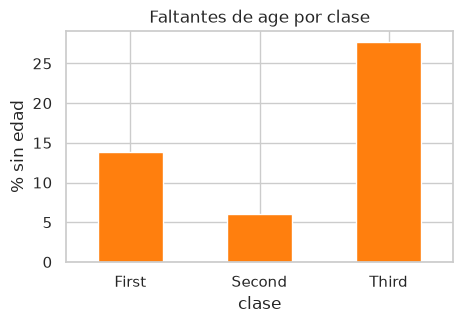

In [5]:
if "por_clase" in globals():
    ax = por_clase.mul(100).plot.bar(color="tab:orange", rot=0, figsize=(5, 3))
    ax.set(ylabel="% sin edad", xlabel="clase", title="Faltantes de age por clase")
    plt.show()

**✅ Respuesta sugerida:**

La falta de `age` es mucho mayor en **tercera clase** (27.7%) que en primera (13.9%) y segunda (6.0%), y también varía por puerto (63.6% en Queenstown). **No parece MCAR**: depende de variables observadas, lo que es compatible con **MAR** (aunque no se puede descartar MNAR). Por eso conviene imputar condicionando en `class` y `sex`.

### 🟢 Ejercicio 3 · Mediana global vs. mediana por `class` y `sex`.

**🎯 Objetivo:** comparar dos imputaciones sobre la distribución. **Qué se espera aprender:** que imputar por grupo respeta mejor la forma de los datos que un valor único.

1. Crea `age_med_global` (imputando con la mediana global) y `age_med_grupo` (con la mediana por `class` y `sex`, usando `groupby(...).transform("median")`), además de un indicador `age_faltaba`.
2. Compara media, mediana y desviación estándar de `age` original y de las dos versiones imputadas.
3. Grafica las tres distribuciones. ¿Qué estrategia distorsiona menos? ¿Qué le pasa a la desviación estándar?

* La siguiente celda muestra una solución posible.

In [6]:
titanic_imp = titanic.assign(
    age_faltaba=lambda d: d["age"].isna(),
    age_med_global=lambda d: d["age"].fillna(d["age"].median()),
    age_med_grupo=lambda d: d["age"].fillna(d.groupby(["class", "sex"])["age"].transform("median")),
)
medianas_grupo = titanic.groupby(["class", "sex"])["age"].median().unstack()
comparacion = titanic_imp[["age", "age_med_global", "age_med_grupo"]].agg(["count", "mean", "median", "std"]).T.round(2)
medianas_grupo, comparacion

(sex     female  male
 class               
 First     35.0  40.0
 Second    28.0  30.0
 Third     21.5  25.0,
                 count   mean  median    std
 age             714.0  29.70    28.0  14.53
 age_med_global  891.0  29.36    28.0  13.02
 age_med_grupo   891.0  29.11    26.0  13.30)

* La siguiente celda graficará las tres distribuciones de edad (requiere `titanic_imp`).

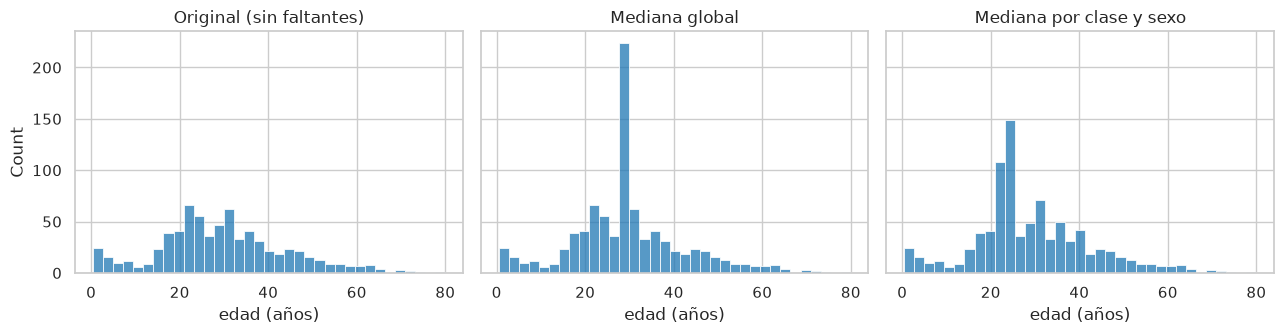

In [7]:
if "titanic_imp" in globals():
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
    for ax, columna, titulo in zip(axes, ["age", "age_med_global", "age_med_grupo"],
                                   ["Original (sin faltantes)", "Mediana global", "Mediana por clase y sexo"]):
        sns.histplot(titanic_imp[columna].dropna(), bins=35, ax=ax, color="tab:blue")
        ax.set(title=titulo, xlabel="edad (años)")
    plt.tight_layout()
    plt.show()

**✅ Respuesta sugerida:**

* La **mediana global** (28 años) mete 177 valores idénticos: aparece una barra enorme en 28 y la desviación estándar baja de 14.5 a 13.0.
* La **mediana por clase y sexo** reparte los imputados entre varios valores (de 21.5 a 40 años), conserva mejor la forma y la relación edad–clase (primera clase es mayor) y reduce menos la desviación estándar (13.3).
* Ambas **subestiman la variabilidad**, porque todos los imputados de un grupo valen lo mismo. Por eso se guarda `age_faltaba`.

### 🔴 Reto 1 · `deck` y `embark_town`, y un adelanto de inferencia.

**🎯 Objetivo:** decidir qué hacer con una columna casi vacía y con una casi completa. **Qué se espera aprender:** que el porcentaje de faltantes cambia por completo la decisión.

1. Propón y aplica un tratamiento para `deck` (77% faltante) y para `embark_town` (2 filas). Justifica.
2. **Adelanto de la sesión 6:** con `pd.crosstab` y `scipy.stats.chi2_contingency`, prueba si la falta de `age` es independiente de `class`. Interpreta el valor *p* con cuidado.
3. ¿La tasa de supervivencia es distinta entre quienes tienen y no tienen `age` registrada? ¿Qué implicaría para un análisis que simplemente borra esas filas?

* La siguiente celda muestra una solución posible.

In [8]:
from scipy import stats

moda_puerto = titanic["embark_town"].mode()[0]
titanic_tratado = titanic.assign(
    deck=lambda d: d["deck"].fillna("Desconocido"),
    embark_town=lambda d: d["embark_town"].fillna(moda_puerto),
)
tabla_edad = pd.crosstab(titanic["class"], titanic["age"].isna().rename("age_faltante"))
chi2, valor_p, grados, esperadas = stats.chi2_contingency(tabla_edad)
supervivencia = titanic["survived"].groupby(titanic["age"].isna().rename("age_faltante")).mean().round(3)
titanic_tratado["deck"].value_counts(), moda_puerto, tabla_edad, round(chi2, 1), f"{valor_p:.2g}", supervivencia

(deck
 Desconocido    688
 C               59
 B               47
 D               33
 E               32
 A               15
 F               13
 G                4
 Name: count, dtype: int64,
 'Southampton',
 age_faltante  False  True 
 class                     
 First           186     30
 Second          173     11
 Third           355    136,
 np.float64(46.1),
 '9.9e-11',
 age_faltante
 False    0.406
 True     0.294
 Name: survived, dtype: float64)

**✅ Respuesta sugerida:**

1. `deck`: categoría explícita `"Desconocido"` (no se inventan cubiertas). `embark_town`: moda (Southampton), porque son solo 2 filas.
2. χ² ≈ 46.1 con 2 grados de libertad y *p* ≈ 1e-10: si la falta fuera independiente de la clase, una asociación así sería muy improbable. Esto **descarta MCAR** respecto a `class`, pero **no prueba** que sea MAR.
3. Sobreviven menos quienes no tienen edad (29.4% contra 40.6%): borrar esas filas **sobrestimaría** la supervivencia.

### Parte B · Auditoría de `penguins` y *dataset* limpio para las siguientes sesiones.

### 🟢 Ejercicio 4 · Aplica la misma auditoría a `penguins` (el original, no `sucio`).

**🎯 Objetivo:** recorrer la lista de verificación completa en un *dataset* real. **Qué se espera aprender:** a producir una auditoría completa, como la que se hace al empezar cualquier EDA.

1. Recorre la lista de verificación: tipos, duplicados, categorías (`value_counts`), rangos y faltantes por columna y por patrón.
2. Identifica las **filas sin medidas** y las filas con **`sex` faltante**. ¿La falta de `sex` se concentra en alguna especie o isla?
3. Decide y justifica: ¿qué haces con las filas sin medidas? ¿Imputas `sex`?

* La siguiente celda muestra una solución posible.

In [9]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
sin_medidas = pinguinos[medidas].isna().all(axis=1)
sexo_falta = pinguinos["sex"].isna()
{
    "duplicados exactos": int(pinguinos.duplicated().sum()),
    "categorías": [pinguinos[c].value_counts(dropna=False).to_dict() for c in ["species", "island", "sex"]],
    "rangos": pinguinos[medidas].agg(["min", "max"]).to_dict(),
    "filas sin medidas": int(sin_medidas.sum()),
    "sex faltante": int(sexo_falta.sum()),
    "sex faltante y sin medidas": int((sexo_falta & sin_medidas).sum()),
    "sex faltante por especie e isla": pinguinos[sexo_falta].groupby(["species", "island"]).size().to_dict(),
}

{'duplicados exactos': 0,
 'categorías': [{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68},
  {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52},
  {'MALE': 168, 'FEMALE': 165, nan: 11}],
 'rangos': {'bill_length_mm': {'min': 32.1, 'max': 59.6},
  'bill_depth_mm': {'min': 13.1, 'max': 21.5},
  'flipper_length_mm': {'min': 172.0, 'max': 231.0},
  'body_mass_g': {'min': 2700.0, 'max': 6300.0}},
 'filas sin medidas': 2,
 'sex faltante': 11,
 'sex faltante y sin medidas': 2,
 'sex faltante por especie e isla': {('Adelie', 'Dream'): 1,
  ('Adelie', 'Torgersen'): 5,
  ('Gentoo', 'Biscoe'): 5}}

**✅ Respuesta sugerida:**

* **Duplicados:** no hay. **Categorías:** consistentes, pero `sex` viene en mayúsculas (`MALE`/`FEMALE`); se pasa a `Male`/`Female` para homologar con *Seaborn* y con `sucio`. **Rangos:** plausibles.
* **2 filas sin ninguna medida** (y sin `sex`): no aportan nada al análisis de medidas, así que **se eliminan** y se documenta (2 de 344, 0.6%).
* **`sex` faltante en 11 filas** (9 tras eliminar las 2 anteriores), todas en Adelie (Torgersen y Dream) y Gentoo; ninguna en Chinstrap. **No se imputa**: inventar el sexo sesgaría las comparaciones por sexo de las sesiones 5 y 6. Se deja como `NaN` y cada análisis por sexo excluye esas filas explícitamente.

### *Dataset* limpio de referencia (`data/penguins_limpio.csv`).

Para que **todos empiecen la sesión 3 con los mismos datos**, la siguiente celda aplica las decisiones acordadas y guarda el resultado. Compárala con lo que hiciste en el ejercicio 4.

Decisiones: (1) `sex` → `Male`/`Female`; (2) eliminar las filas sin ninguna medida; (3) **no** imputar `sex`; (4) tipos: `category` para las categóricas y `Float64` para aleta y masa, porque son **medidas continuas**: se anotan en milímetros y gramos enteros, pero no son conteos. Por eso en el archivo aparecen con decimal (por ejemplo, `181.0`).

* La siguiente celda construirá `penguins_limpio` y lo guardará en `data/`.

In [10]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins_limpio = (
    pinguinos
    .assign(sex=lambda d: d["sex"].str.title())
    .dropna(subset=medidas, how="all")
    .astype({"species": "category", "island": "category", "sex": "category",
             "flipper_length_mm": "Float64", "body_mass_g": "Float64"})
    .reset_index(drop=True)
)
penguins_limpio.to_csv(os.path.join(DATA, "penguins_limpio.csv"), index=False)
len(pinguinos), len(penguins_limpio), penguins_limpio.isna().sum().to_dict()

(344,
 342,
 {'species': 0,
  'island': 0,
  'bill_length_mm': 0,
  'bill_depth_mm': 0,
  'flipper_length_mm': 0,
  'body_mass_g': 0,
  'sex': 9})

### 🔴 Reto 2 · Impacto de las decisiones.

**🎯 Objetivo:** comparar resultados con distintas decisiones de limpieza. **Qué se espera aprender:** a reportar si una decisión cambia o no las conclusiones.

Compara la masa media por especie y sexo en `pinguinos` (original) y en `penguins_limpio`. ¿Cambió algo? ¿Por qué era de esperarse? Después calcula cuánto cambiaría la masa media por especie y sexo si se hubiera imputado `sex` con la **moda** de cada especie: ¿qué sexo "gana" artificialmente?

* La siguiente celda muestra una solución posible.

In [11]:
original = pinguinos.assign(sex=lambda d: d["sex"].str.title()).groupby(["species", "sex"])["body_mass_g"].mean()
limpia = penguins_limpio.groupby(["species", "sex"], observed=True)["body_mass_g"].mean()

moda_sexo = penguins_limpio.groupby("species", observed=True)["sex"].agg(lambda s: s.mode()[0]).astype("str")
sexo_imputado = penguins_limpio["sex"].astype("str").fillna(penguins_limpio["species"].astype("str").map(moda_sexo))
imputado = penguins_limpio.assign(sex=sexo_imputado)

pd.concat({
    "original": original,
    "limpio": limpia,
    "sex imputado con la moda": imputado.groupby(["species", "sex"])["body_mass_g"].mean(),
    "n tras imputar": imputado.groupby(["species", "sex"]).size(),
}, axis=1).round(1)

original  limpio  sex imputado con la moda  n tras imputar
species   sex                                                               
Adelie    Female    3368.8  3368.8                    3379.8              78
          Male      4043.5  4043.5                    4043.5              73
Chinstrap Female    3527.2  3527.2                    3527.2              34
          Male      3939.0  3939.0                    3939.0              34
Gentoo    Female    4679.7  4679.7                    4679.7              58
          Male      5484.8  5484.8                    5429.6              65

**✅ Respuesta sugerida:**

Original y limpio coinciden: las filas eliminadas no tenían medidas, así que no entraban en ningún promedio. Al imputar con la moda, todos los faltantes de Adelie pasan a `Female` y los de Gentoo a `Male`. **Ojo con Adelie:** entre los que tienen sexo registrado hay un **empate** (73 machos y 73 hembras), así que en realidad no hay un sexo "más común"; `mode()` devuelve los dos y `[0]` toma el primero en orden alfabético (`Female`). La decisión fue arbitraria, lo que refuerza que no conviene imputar `sex`. Esos grupos se inflan y mezclan individuos que pueden ser del otro sexo (por ejemplo, la masa media de los machos Gentoo baja de 5484.8 a 5429.6 g), lo que sesga las comparaciones.

---
## ✅ Cierre.

**Hoy vimos:**
* La **lista de verificación de calidad** que se usará en todo el curso.
* Duplicados exactos vs. por llave, y por qué un duplicado sin llave no siempre es un error (`titanic`).
* Inconsistencias: texto, categorías, códigos centinela, rangos imposibles y unidades.
* Mecanismos **MCAR / MAR / MNAR** y cómo perfilarlos.
* Tratamientos y su costo: eliminar sesga si no es MCAR; imputar con un valor único **encoge la varianza** y **atenúa las correlaciones**; imputar por grupo es mejor si la causa está observada; conviene guardar el indicador.
* Decidir antes de limpiar: cuántos faltan, de qué depende la falta, para qué se usará la variable y qué población queda después de eliminar filas.

**Práctica (en Classroom):** terminar los ejercicios 🟢 y verificar que exista `data/penguins_limpio.csv`.

**Siguiente *notebook*:** `10_tendencia_central_y_dispersion.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>